# Image Colorization with a U-Net (PyTorch)

I wanted to see how well a small neural network can guess the colors of a black and white picture. This notebook trains a U-Net on CIFAR-10 and checks the result with numbers (PSNR and SSIM), not just by looking at a few nice samples.

**How it works**
- Convert every image from RGB to LAB color space. The `L` channel is the brightness, which is basically the grayscale picture. The `a` and `b` channels hold the color.
- Give the network only `L` and ask it to predict `a` and `b`.
- Stick the predicted colors back onto `L`, convert to RGB, and compare with the real image.

**Running it:** on Colab go to Runtime > Change runtime type and pick a GPU. On a T4 the whole notebook takes around 15 to 20 minutes. On a CPU it will crawl.

In [12]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from skimage.color import rgb2lab, lab2rgb
from skimage.metrics import structural_similarity

# settings i change most often
EPOCHS = 25
BATCH_SIZE = 128
LR = 2e-3
BASE = 64          # width of the first conv layer, everything else scales from it
VAL_SIZE = 5000    # images taken out of the training set for validation

# skimage complains when the model predicts a color that doesn't exist in RGB, it clips it anyway
warnings.filterwarnings("ignore", message=".*Conversion from CIE-LAB.*")

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("running on", device)

running on cuda


## 1. Data

CIFAR-10 has 50,000 training and 10,000 test images, all 32x32. I only need the pictures here, the class labels come back later when I look at which kinds of images are easy or hard to colorize.

In [13]:
# i use the huggingface copy of CIFAR-10 because the original server is really slow on Colab
cifar = load_dataset("uoft-cs/cifar10")


def to_numpy(split):
    # every image comes as a PIL picture, so stack them all into one big array
    return np.stack([np.array(img) for img in split["img"]]).astype("uint8")


x_train_rgb = to_numpy(cifar["train"])
x_test_rgb = to_numpy(cifar["test"])
test_labels = np.array(cifar["test"]["label"])
classes = cifar["train"].features["label"].names

print(x_train_rgb.shape, x_test_rgb.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


### RGB to LAB

Neural networks train better when the numbers are small and centered around zero, so I scale both parts:
- `L` goes from 0..100 to -1..1
- `a` and `b` go from roughly -128..127 to roughly -1..1

The model ends with a `tanh`, which also gives -1..1, so the output range matches the targets. (My first attempt at this project used a sigmoid on unscaled LAB values and the loss never moved. That mismatch was the whole problem.)

In [14]:
def rgb_to_lab_tensors(rgb_uint8):
    lab = rgb2lab(rgb_uint8 / 255.0)
    L = lab[..., 0] / 50.0 - 1.0
    ab = lab[..., 1:] / 128.0
    L = torch.from_numpy(L).float().unsqueeze(1)          # (N, 1, H, W)
    ab = torch.from_numpy(ab).float().permute(0, 3, 1, 2)  # (N, 2, H, W)
    return L, ab


def convert_in_chunks(rgb, chunk=5000):
    # doing all 50k images at once eats a lot of RAM, so go in pieces
    Ls, abs_ = [], []
    for i in range(0, len(rgb), chunk):
        L, ab = rgb_to_lab_tensors(rgb[i:i + chunk])
        Ls.append(L)
        abs_.append(ab)
    return torch.cat(Ls), torch.cat(abs_)


def lab_tensors_to_rgb(L, ab):
    # undo the scaling and go back to RGB, returns (N, H, W, 3) floats in 0..1
    L = (L.cpu().numpy() + 1.0) * 50.0
    ab = ab.cpu().numpy() * 128.0
    lab = np.concatenate([L, ab], axis=1).transpose(0, 2, 3, 1)
    return lab2rgb(lab)


L_train, ab_train = convert_in_chunks(x_train_rgb)
L_test, ab_test = convert_in_chunks(x_test_rgb)

print("L:", L_train.shape, "ab:", ab_train.shape)
print("L range:", L_train.min().item(), L_train.max().item())
print("ab range:", ab_train.min().item(), ab_train.max().item())

L: torch.Size([50000, 1, 32, 32]) ab: torch.Size([50000, 2, 32, 32])
L range: -1.0 1.0
ab range: -0.8426351547241211 0.7674457430839539


In [15]:
# quick sanity check, converting there and back should give the same picture
check = lab_tensors_to_rgb(L_train[:100], ab_train[:100])
print("round trip error:", np.abs(check - x_train_rgb[:100] / 255.0).max())

round trip error: 1.6640506538684319e-06


In [16]:
# split off a validation set so i can pick the best epoch without touching the test set
perm = torch.randperm(len(L_train))
val_idx, tr_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]

train_loader = DataLoader(TensorDataset(L_train[tr_idx], ab_train[tr_idx]),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(L_train[val_idx], ab_train[val_idx]),
                        batch_size=BATCH_SIZE)

print(len(tr_idx), "train /", len(val_idx), "val /", len(L_test), "test")

45000 train / 5000 val / 10000 test


## 2. Model

A small U-Net. The encoder shrinks the image (32 -> 16 -> 8 -> 4) so the network can see the bigger picture, like "this looks like sky" or "this is a frog on grass". The decoder blows it back up to 32x32. The skip connections pass the sharp detail from the encoder straight to the decoder so edges don't get blurry.

The old Keras version was just a stack of 3x3 convolutions at full size, so every pixel only saw a tiny neighborhood. It had no way of knowing what the object was.

In [17]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, base=64):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        self.enc1 = conv_block(1, base)              # 32x32
        self.enc2 = conv_block(base, base * 2)       # 16x16
        self.enc3 = conv_block(base * 2, base * 4)   # 8x8
        self.bottom = conv_block(base * 4, base * 8) # 4x4

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = conv_block(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = conv_block(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = conv_block(base * 2, base)

        self.out = nn.Conv2d(base, 2, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottom(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.tanh(self.out(d1))


model = UNet(BASE).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

# make sure the shapes line up before spending time on training
print(model(L_train[:4].to(device)).shape)

7,699,074 parameters
torch.Size([4, 2, 32, 32])


## 3. Training

L1 loss instead of MSE. With MSE the network plays it safe and predicts the average color, which is why a lot of colorizers give you dull brown and gray pictures. L1 is a bit less afraid of committing to a color.

In [18]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def run_epoch(loader, training):
    model.train(training)
    total, seen = 0.0, 0
    with torch.set_grad_enabled(training):
        for L, ab in loader:
            L, ab = L.to(device), ab.to(device)
            loss = loss_fn(model(L), ab)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(L)
            seen += len(L)
    return total / seen

In [19]:
history = {"train": [], "val": []}
best_val = float("inf")

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)
    scheduler.step()

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    # keep the weights from the best epoch, not just the last one
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "colorizer_unet.pt")

    print(f"epoch {epoch:2d}/{EPOCHS}  train {train_loss:.4f}  val {val_loss:.4f}  ({time.time() - start:.0f}s)")

model.load_state_dict(torch.load("colorizer_unet.pt", map_location=device))
print("best val loss:", round(best_val, 4))

epoch  1/25  train 0.0706  val 0.0653  (45s)
epoch  2/25  train 0.0648  val 0.0662  (42s)
epoch  3/25  train 0.0642  val 0.0638  (43s)
epoch  4/25  train 0.0635  val 0.0630  (43s)
epoch  5/25  train 0.0631  val 0.0627  (42s)
epoch  6/25  train 0.0630  val 0.0631  (43s)
epoch  7/25  train 0.0625  val 0.0633  (43s)
epoch  8/25  train 0.0622  val 0.0628  (43s)
epoch  9/25  train 0.0618  val 0.0628  (43s)
epoch 10/25  train 0.0614  val 0.0620  (43s)
epoch 11/25  train 0.0611  val 0.0624  (42s)
epoch 12/25  train 0.0606  val 0.0615  (42s)
epoch 13/25  train 0.0601  val 0.0613  (42s)
epoch 14/25  train 0.0596  val 0.0611  (43s)
epoch 15/25  train 0.0590  val 0.0617  (42s)
epoch 16/25  train 0.0581  val 0.0614  (42s)
epoch 17/25  train 0.0572  val 0.0613  (42s)
epoch 18/25  train 0.0561  val 0.0613  (42s)
epoch 19/25  train 0.0549  val 0.0620  (43s)
epoch 20/25  train 0.0538  val 0.0620  (43s)
epoch 21/25  train 0.0528  val 0.0620  (43s)
epoch 22/25  train 0.0520  val 0.0621  (43s)
epoch 23/2

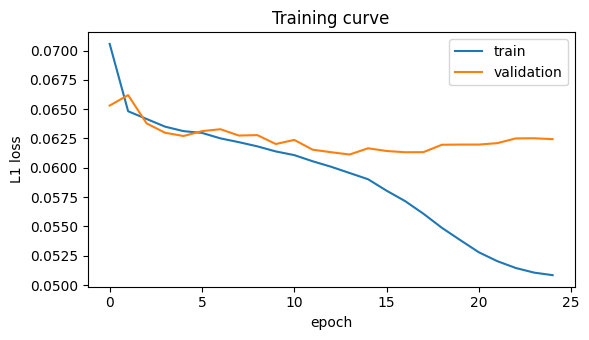

In [20]:
plt.figure(figsize=(6, 3.5))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("epoch")
plt.ylabel("L1 loss")
plt.title("Training curve")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Evaluation

Looking at samples is nice but it's easy to cherry pick, so I score the whole 10,000 image test set. Two metrics:
- **PSNR** (higher is better): how close the pixels are to the real image.
- **SSIM** (higher is better, max 1): how similar the structure and texture are.

I also need something to compare against. The obvious baseline is to do nothing, meaning the grayscale image with zero color (`a = b = 0`). If the model can't beat that, it hasn't learned anything useful.

In [21]:
@torch.no_grad()
def predict_ab(L, batch_size=500):
    model.eval()
    out = []
    for i in range(0, len(L), batch_size):
        out.append(model(L[i:i + batch_size].to(device)).cpu())
    return torch.cat(out)


def psnr_per_image(a, b):
    mse = ((a - b) ** 2).reshape(len(a), -1).mean(axis=1)
    return 10 * np.log10(1.0 / np.maximum(mse, 1e-10))


def ssim_per_image(a, b):
    return np.array([structural_similarity(x, y, channel_axis=2, data_range=1.0)
                     for x, y in zip(a, b)])


true_rgb = x_test_rgb / 255.0
pred_ab = predict_ab(L_test)

pred_rgb = lab_tensors_to_rgb(L_test, pred_ab)
gray_rgb = lab_tensors_to_rgb(L_test, torch.zeros_like(ab_test))   # baseline, no color at all

psnr_model = psnr_per_image(pred_rgb, true_rgb)
psnr_base = psnr_per_image(gray_rgb, true_rgb)
ssim_model = ssim_per_image(pred_rgb, true_rgb)
ssim_base = ssim_per_image(gray_rgb, true_rgb)

# error on the color channels themselves, in normal LAB units
ab_err_model = (pred_ab - ab_test).abs().mean().item() * 128
ab_err_base = ab_test.abs().mean().item() * 128

print(f"{'':22s}{'grayscale':>12s}{'U-Net':>12s}")
print(f"{'PSNR (dB)':22s}{psnr_base.mean():12.2f}{psnr_model.mean():12.2f}")
print(f"{'SSIM':22s}{ssim_base.mean():12.4f}{ssim_model.mean():12.4f}")
print(f"{'mean abs error (a,b)':22s}{ab_err_base:12.2f}{ab_err_model:12.2f}")

                         grayscale       U-Net
PSNR (dB)                    24.81       25.34
SSIM                        0.9310      0.9378
mean abs error (a,b)          9.29        7.82


In [22]:
better = (psnr_model > psnr_base).mean() * 100
print(f"the model beats the grayscale baseline on {better:.1f}% of test images")

the model beats the grayscale baseline on 69.7% of test images


### Which classes does it do well on?

Some things have a pretty fixed color (sky, grass, water) and some don't (a car can be any color). I would expect the model to help most on the first kind.

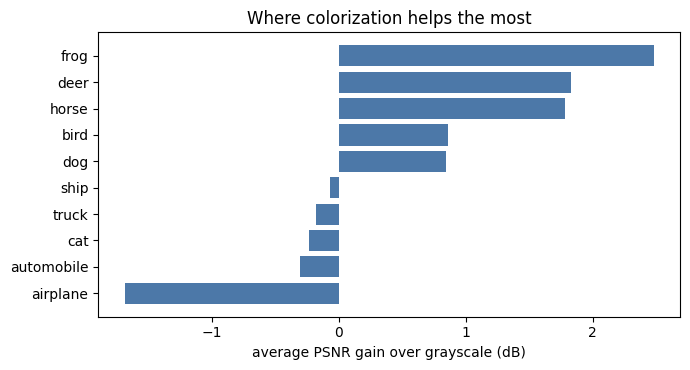

biggest gain: frog 2.48 dB
smallest gain: airplane -1.69 dB


In [23]:
labels = np.array(test_labels)
gain = psnr_model - psnr_base

class_gain = np.array([gain[labels == c].mean() for c in range(len(classes))])
order = np.argsort(class_gain)

plt.figure(figsize=(7, 3.8))
plt.barh([classes[i] for i in order], class_gain[order], color="#4c78a8")
plt.xlabel("average PSNR gain over grayscale (dB)")
plt.title("Where colorization helps the most")
plt.tight_layout()
plt.show()

print("biggest gain:", classes[order[-1]], round(class_gain[order[-1]], 2), "dB")
print("smallest gain:", classes[order[0]], round(class_gain[order[0]], 2), "dB")

## 5. Samples

Top row is what the model sees, middle row is what it predicts, bottom row is the real image. These are the first 10 test images, not hand picked.

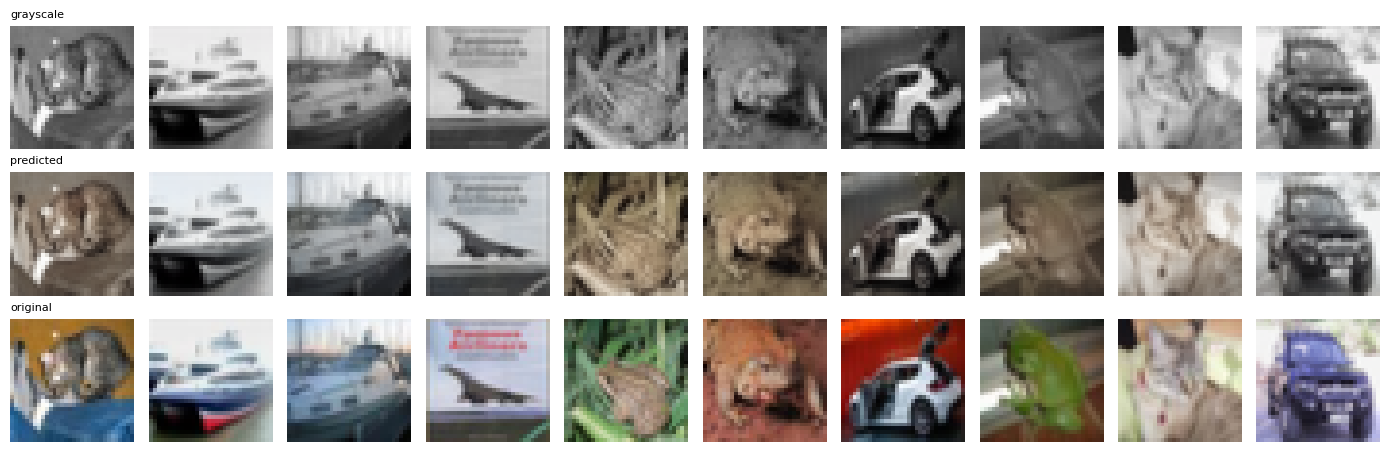

In [24]:
n = 10
fig, axes = plt.subplots(3, n, figsize=(n * 1.4, 4.6))

for i in range(n):
    axes[0, i].imshow(gray_rgb[i])
    axes[1, i].imshow(pred_rgb[i])
    axes[2, i].imshow(true_rgb[i])
    for row in range(3):
        axes[row, i].axis("off")

axes[0, 0].set_title("grayscale", fontsize=8, loc="left")
axes[1, 0].set_title("predicted", fontsize=8, loc="left")
axes[2, 0].set_title("original", fontsize=8, loc="left")

plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()

## 6. Results and limitations

Scores on the 10,000 test images:

| Metric | Grayscale baseline | U-Net |
|---|---|---|
| PSNR (dB) | 24.81 | 25.34 |
| SSIM | 0.931 | 0.938 |
| Mean abs error (a, b) | 9.29 | 7.82 |

The model beats the grayscale baseline on 69.7% of the test images and cuts the color error by about 16%. The PSNR and SSIM gains look small because CIFAR-10 pictures are already fairly muted, so plain grayscale scores high to begin with. The color error is the fairest number for what the model actually learned.

**Overfitting:** the validation loss was lowest at epoch 14 (0.0611) and crept up after that while the training loss kept dropping. I kept the weights from the best epoch, so the scores above come from that one. Random flips or fewer epochs would probably help.

Things that are worth being honest about:
- The images are only 32x32. At that size there is not much detail for the network to work with, and the output looks soft.
- Colorization has no single right answer. A shirt can be red or blue and the grayscale looks the same. The model picks the most likely color, so the output tends to be a bit washed out. This is a known problem with regression based colorizers.
- It was trained on CIFAR-10 only, so don't expect it to work well on big photos of other things.

**What I would try next**
- Add random flips (data augmentation) to reduce the overfitting.
- Train on a bigger dataset (like a resized subset of ImageNet or Places) at 128x128 or more.
- Add a GAN loss or a perceptual loss to get more vivid colors.
- Treat colors as classification over bins instead of regression, like the Zhang et al. paper does.